**K-MEANS CLUSTERING MODEL**

In [2]:
# Importing all the necessary dependencies
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

import sklearn.compose
from sklearn.compose import ColumnTransformer 

import sklearn.impute
from sklearn.impute import SimpleImputer

import sklearn.pipeline
from sklearn.pipeline import Pipeline

import sklearn.model_selection
from sklearn.model_selection import train_test_split

import sklearn.preprocessing
from sklearn.preprocessing import StandardScaler

import sklearn.cluster 
from sklearn.cluster import KMeans

In [3]:
df = pd.read_csv('3) Sentiment dataset.csv')

In [4]:
df.head()

,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,3,3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,4,4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19


In [5]:
# Picking a feature(s) and scaling it
X= df[['Hour', 'Likes']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [6]:
# Running or Training the model
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

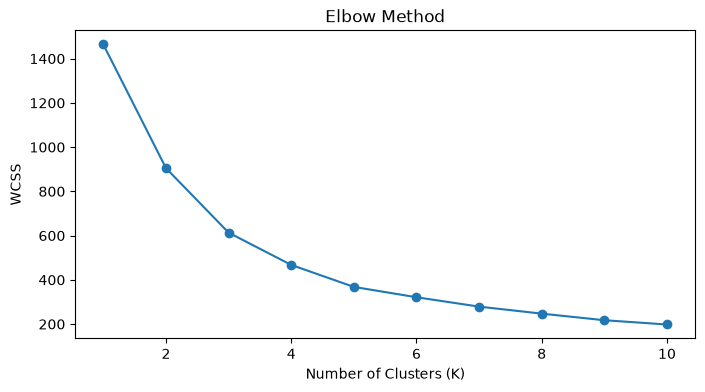

In [7]:
# Graphical Representation of the trained model: Elbow Method
plt.figure(figsize=[8, 4])
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

In [8]:
# Predicting and Testing the Model
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
labels = kmeans_final.fit_predict(X_scaled)

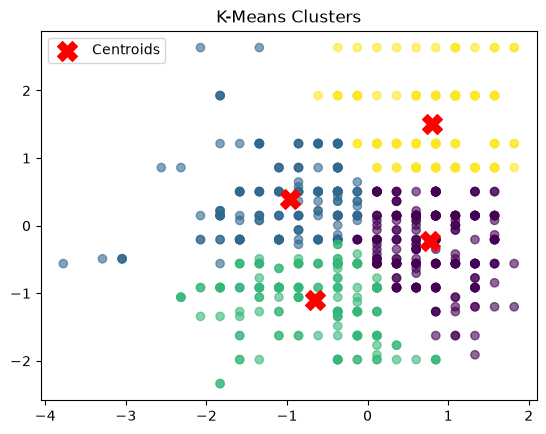

In [9]:
# Graphical Representation of the Model Showing the data point and the point of clusters(Centroids)
plt.scatter(
    X_scaled[:, 0], X_scaled[:, 1], c=labels, cmap="viridis", alpha=0.6
)

plt.scatter(
    kmeans_final.cluster_centers_[:, 0],
    kmeans_final.cluster_centers_[:, 1],
    s=200,
    c="red",
    marker='X',
    label='Centroids'
)
plt.legend()
plt.title('K-Means Clusters')
plt.show()

In [10]:
# Cluster Summary
df['Cluster'] = labels

cluster_summary = df.groupby('Cluster')[['Hour', 'Likes']].mean()
cluster_summary['Count'] = df['Cluster'].value_counts()

print('---Cluster Profiles (Real-World Average)---')
print(cluster_summary.round(2))

---Cluster Profiles (Real-World Average)---
          Hour  Likes  Count
Cluster                     
0        18.69  39.61    254
1        11.57  48.47    184
2        12.85  27.41    175
3        18.82  64.12    119
